In [4]:
from pathlib import Path 
from collections import Counter

PROJECT_ROOT = Path.cwd().parent

DET_RAW = PROJECT_ROOT / "data" / "detection" / "raw"
DET_DIR = PROJECT_ROOT / "data" / "detection" / "dataest"


print("PROJECT_ROOT:", PROJECT_ROOT)
print("DET_RAW exists:", DET_RAW.exists())

PROJECT_ROOT: c:\Users\ycode\Desktop\brain-tumor-project
DET_RAW exists: True


In [5]:
for d in sorted(p for p in DET_RAW.rglob("*") if p.is_dir()):
    n = sum(1 for f in d.iterdir() if f.is_file())
    if n:
        print(f"{str(d.relative_to(DET_RAW)):45s} {n:5d} files")

print("\n Class IDs found in labels:")
ids = {}

for f in DET_RAW.rglob("*.txt"):
    for line in f.read_text().splitlines():
        if line.strip():
            ids.setdefault(str(f.parent.relative_to(DET_RAW)), Counter())[line.split()[0]] += 1
for k, v in sorted(ids.items()):
    print(f"{k:45s} {dict(v)}")

ex = next(DET_RAW.rglob("*.txt"))
print("\nExample:", ex.name)
print(ex.read_text()[:300])

Train\Glioma\images                            1153 files
Train\Glioma\labels                            1153 files
Train\Meningioma\images                        1449 files
Train\Meningioma\labels                        1449 files
Train\No Tumor\images                           711 files
Train\No Tumor\labels                           711 files
Train\Pituitary\images                         1424 files
Train\Pituitary\labels                         1424 files
Val\Glioma\images                               136 files
Val\Glioma\labels                               136 files
Val\Meningioma\images                           140 files
Val\Meningioma\labels                           140 files
Val\No Tumor\images                             100 files
Val\No Tumor\labels                             100 files
Val\Pituitary\images                            136 files
Val\Pituitary\labels                            136 files

 Class IDs found in labels:
Train\Glioma\labels                        

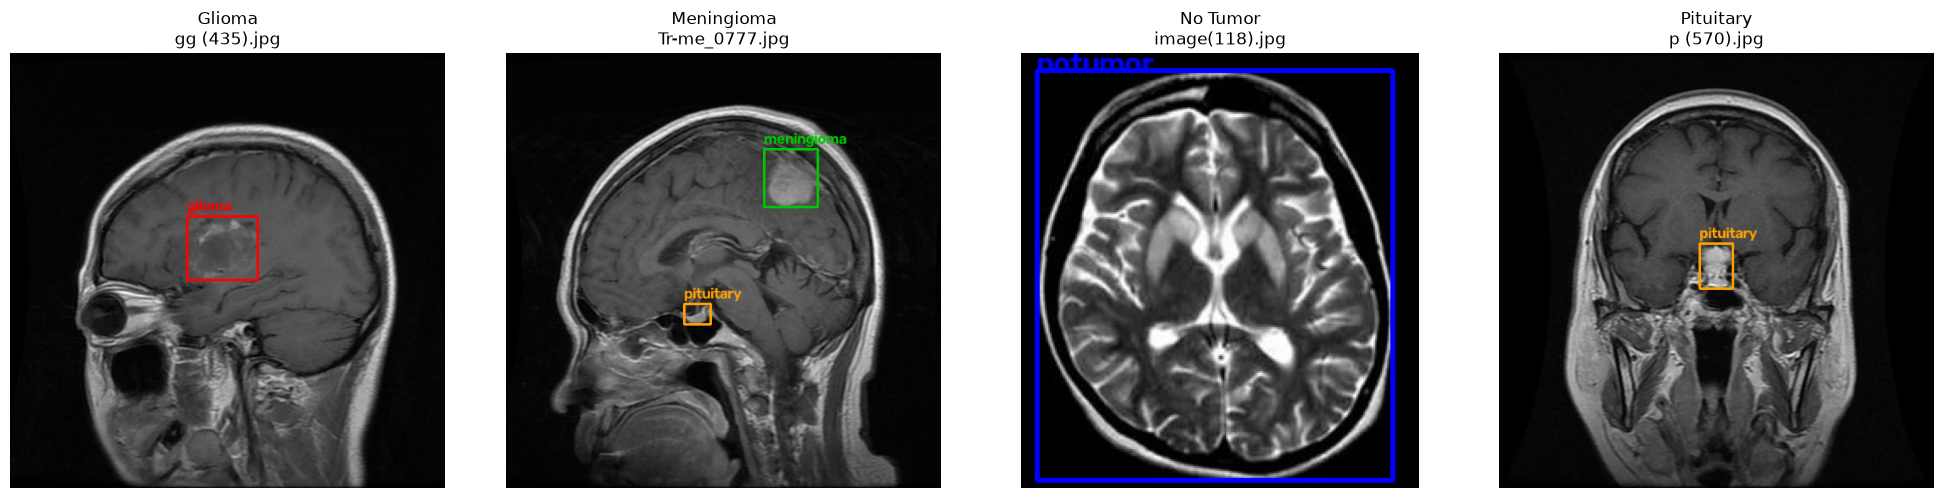

In [6]:
import random, cv2
import matplotlib.pyplot as plt

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]   # IDs 0..3
COLORS = [(255, 0, 0), (0, 200, 0), (0, 0, 255), (255, 160, 0)]

def draw(img_path, lbl_path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in lbl_path.read_text().splitlines():
        if not line.strip():
            continue
        c, xc, yc, bw, bh = line.split()[:5]
        c = int(c)
        x1, y1 = int((float(xc) - float(bw) / 2) * w), int((float(yc) - float(bh) / 2) * h)
        x2, y2 = int((float(xc) + float(bw) / 2) * w), int((float(yc) + float(bh) / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[c], 2)
        cv2.putText(img, CLASS_NAMES[c], (x1, max(y1 - 6, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, COLORS[c], 2)
    return img

random.seed(1)
folders = sorted((DET_RAW / "Train").iterdir())
fig, axes = plt.subplots(1, len(folders), figsize=(5 * len(folders), 5))

for ax, folder in zip(axes, folders):
    img_path = random.choice(list((folder / "images").glob("*")))
    lbl_path = folder / "labels" / (img_path.stem + ".txt")
    ax.imshow(draw(img_path, lbl_path))
    ax.set_title(f"{folder.name}\n{img_path.name}")
    ax.axis("off")

plt.tight_layout()
(PROJECT_ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "yolo_samples.png", dpi=150)
plt.show()

In [7]:
import pandas as pd

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
NAME_TO_ID = {"glioma": 0, "meningioma": 1, "no tumor": 2, "pituitary": 3}

rows, problems = [], []

for split_dir in sorted(DET_RAW.iterdir()):
    for cls_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        imgs = {p.stem: p for p in (cls_dir / "images").iterdir() if p.suffix.lower() in IMG_EXT}
        lbls = {p.stem: p for p in (cls_dir / "labels").glob("*.txt")}

        # Step 13: match by base name
        for s in imgs.keys() - lbls.keys():
            problems.append((split_dir.name, cls_dir.name, s, "image without label"))
        for s in lbls.keys() - imgs.keys():
            problems.append((split_dir.name, cls_dir.name, s, "label without image"))

        # Step 14: validate each matched label file
        for s in imgs.keys() & lbls.keys():
            lines = [l.split() for l in lbls[s].read_text().splitlines() if l.strip()]
            err = None
            if not lines:
                err = "empty label"
            else:
                for v in lines:
                    if len(v) != 5:
                        err = "not 5 values"; break
                    try:
                        c, vals = int(v[0]), list(map(float, v[1:]))
                    except ValueError:
                        err = "non-numeric"; break
                    if c not in range(4):
                        err = f"bad class id {c}"; break
                    if not all(0 <= x <= 1 for x in vals) or vals[2] <= 0 or vals[3] <= 0:
                        err = "coords out of [0,1]"; break
            if err:
                problems.append((split_dir.name, cls_dir.name, s, err))
            else:
                ids = {int(v[0]) for v in lines}
                rows.append({
                    "split": split_dir.name.lower(), "folder": cls_dir.name,
                    "stem": s, "img": str(imgs[s]), "lbl": str(lbls[s]),
                    "main_id": NAME_TO_ID[cls_dir.name.lower()],
                    "ids": ids,
                })

valid = pd.DataFrame(rows)
prob = pd.DataFrame(problems, columns=["split", "folder", "stem", "problem"])

print("Valid pairs:", len(valid), "| Problems:", len(prob))
print(prob["problem"].value_counts() if len(prob) else "No problems found")

# Class consistency: does the folder's main class appear in its labels?
valid["consistent"] = [m in i for m, i in zip(valid["main_id"], valid["ids"])]
print("\nFolder/label inconsistent:", (~valid["consistent"]).sum())

# Same file name in two folders would collide when we merge them
print("Duplicate base names across folders:", valid["stem"].duplicated().sum())

print("\nPairs per split and class:")
print(valid.groupby(["split", "folder"]).size().unstack(0))

Valid pairs: 5246 | Problems: 5
problem
image without label    2
label without image    2
empty label            1
Name: count, dtype: int64

Folder/label inconsistent: 15
Duplicate base names across folders: 0

Pairs per split and class:
split       train  val
folder                
Glioma       1153  135
Meningioma   1449  140
No Tumor      711   98
Pituitary    1424  136


In [8]:
import shutil, yaml
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# 1. Drop inconsistent files
clean = valid[valid["consistent"]].copy()

# 2. Train = original train. Val is split 50/50 into valid and test (stratified)
train_part = clean[clean["split"] == "train"].assign(subset="train")
val_part   = clean[clean["split"] == "val"]
v_df, t_df = train_test_split(val_part, test_size=0.5, stratify=val_part["main_id"], random_state=42)
final = pd.concat([train_part, v_df.assign(subset="valid"), t_df.assign(subset="test")])

# 3. Build images/ and labels/ folders
if DET_DIR.exists():
    shutil.rmtree(DET_DIR)

for _, r in tqdm(final.iterrows(), total=len(final), desc="Copying"):
    for kind, src in [("images", r["img"]), ("labels", r["lbl"])]:
        dst = DET_DIR / kind / r["subset"] / Path(src).name
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)

# 4. Count images and labels per subset
for s in ["train", "valid", "test"]:
    ni = len(list((DET_DIR / "images" / s).glob("*")))
    nl = len(list((DET_DIR / "labels" / s).glob("*.txt")))
    print(f"{s:6s} images: {ni:5d} | labels: {nl:5d}")

# 5. data.yaml
data_cfg = {
    "path": ".",
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": 4,
    "names": CLASS_NAMES,
}
with open(DET_DIR / "data.yaml", "w") as f:
    yaml.dump(data_cfg, f, sort_keys=False)

print("\n", (DET_DIR / "data.yaml").read_text())

shutil.make_archive(str(PROJECT_ROOT / "det_data"), "zip", DET_DIR)
print("Created:", PROJECT_ROOT / "det_data.zip")

Copying: 100%|██████████| 5231/5231 [00:20<00:00, 260.86it/s]


train  images:  4722 | labels:  4722
valid  images:   254 | labels:   254
test   images:   255 | labels:   255

 path: .
train: images/train
val: images/valid
test: images/test
nc: 4
names:
- glioma
- meningioma
- notumor
- pituitary

Created: c:\Users\ycode\Desktop\brain-tumor-project\det_data.zip


In [ ]:
import yaml
cfg = yaml.safe_load(open("/content/dataset/data.yaml"))
cfg["path"] = "/content/dataset"
yaml.dump(cfg, open("/content/dataset/data.yaml", "w"), sort_keys=False)
print(open("/content/dataset/data.yaml").read())

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")          # use yolov8n.pt if you want it faster

results = model.train(
    data="/content/dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,            # early stopping
    project="/content/runs",
    name="yolov8s_brain",
    seed=42,

    # Augmentation (Step 17)
    hsv_h=0.015, hsv_s=0.5, hsv_v=0.3,   # color jitter
    fliplr=0.5,                          # horizontal flip
    flipud=0.0,                          # no vertical flip (MRI orientation matters)
    degrees=10,                          # small rotation
    translate=0.1,
    scale=0.3,
    mosaic=1.0,
    close_mosaic=10,                     # turn mosaic off for the last 10 epochs
)

In [ ]:
from ultralytics import YOLO

best = YOLO("/content/runs/yolov8s_brain/weights/best.pt")
m = best.val(data="/content/dataset/data.yaml", split="test", project="/content/runs", name="test_eval")

print(f"Precision : {m.box.mp:.3f}")
print(f"Recall    : {m.box.mr:.3f}")
print(f"mAP@0.5   : {m.box.map50:.3f}")
print(f"mAP@0.5:0.95: {m.box.map:.3f}")

# Speed: 2.5ms preprocess, 11.6ms inference, 0.0ms loss, 0.9ms postprocess per image
# Results saved to /content/runs/test_eval
# Precision : 0.956
# Recall    : 0.931
# mAP@0.5   : 0.959
# mAP@0.5:0.95: 0.749